In [19]:
import gymnasium as gym 
import random 
import torch 
import numpy  as np
import matplotlib
import matplotlib.pyplot as plt 
from collections import  deque , namedtuple
import math
import os 


In [20]:
# env define import from gymnasium  
env = gym.make("CartPole-v1" )
device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu"
if 'inline' in matplotlib.get_backend() :
    from IPython.display import display, clear_output


In [21]:
Experience = namedtuple('Experience', ['state' , 'action' , 'reward' , 'next_state'])

class ReplayMemory() :
    def __init__(self , capacity):
        self.capacity = capacity
        self.memory = deque([] , maxlen=self.capacity)

    def push(self ,*args) :
        self.memory.append(Experience(*args))

    def sample(self , batchSize=128) :
        return   random.sample(self.memory , batchSize)

    def __len__(self):
        return len(self.memory)

In [22]:
# neural network def 
class  DQN(torch.nn.Module):
    def __init__(self , obs, actions ) :
        super(DQN , self).__init__()
        self.layerStack = torch.nn.Sequential(
            torch.nn.Linear(obs , 128 ) ,
            torch.nn.ReLU() ,
            torch.nn.Linear(128 , 128 ) ,
            torch.nn.ReLU() ,
            torch.nn.Linear(128,actions)
        )
    def forward(self , x) :
         return  self.layerStack(x)

     


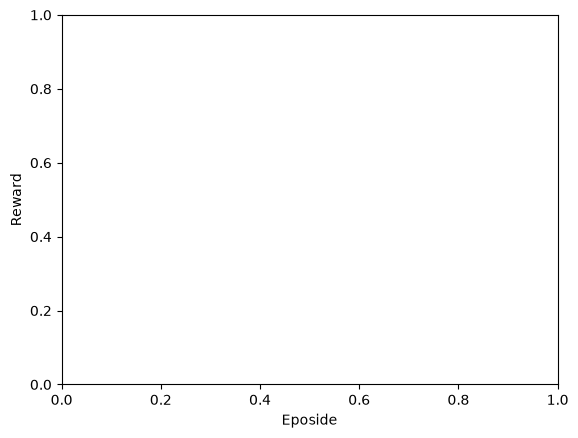

In [27]:
episode_durations = []
# activate interactive mode 
plt.ion()
plt.figure(1)
plt.xlabel('Eposide')
plt.ylabel('Reward')

def plot_durations(show_result=False):
    plt.figure(1)
    durations_t = torch.tensor(episode_durations, dtype=torch.float)
    if show_result:
        plt.title("Result")
    else :
        plt.title("Training")
    #  update the plots 
    plt.plot( durations_t.numpy())
    # Take 100 episode averages and plot them too
    if len( durations_t) >= 100:
        means = durations_t.unfold(0, 100, 1).mean(1).view(-1)
        means = torch.cat((torch.zeros(99), means))
        plt.plot(means.numpy())

    plt.pause(0.005)
    if 'inline' in matplotlib.get_backend() :
        display(plt.gcf())
        clear_output(wait=True)
    else :
        plt.figure(1)
        plt.show(block=False)

 




In [24]:
BATCH_SIZE = 128
GAMMA = 0.99
EPS_START = 0.9
EPS_END = 0.01
EPS_DECAY = 2500
TAU = 0.005
LR = 3e-4


# Get number of actions from gym action space
n_actions = env.action_space.n
# Get the number of state observations
state, info = env.reset()
n_observations = len(state)

policy_net = DQN(n_observations, n_actions).to(device)
target_net = DQN(n_observations, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())

optimizer = torch.optim.AdamW(policy_net.parameters(), lr=LR, amsgrad=True)
memory = ReplayMemory(10000)

steps_done = 0 

def select_action(state):
    global steps_done
    sample = random.random()
    eps_threshold = EPS_END + (EPS_START - EPS_END) * \
        math.exp(-1. * steps_done / EPS_DECAY)
    steps_done += 1
    if sample > eps_threshold:
        with torch.no_grad():
            return policy_net(state).max(1).indices.view(1, 1)
    else:
        return torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)


In [25]:
#  update the policy model params loop 
def optimize_model() :
    # check if memory > batch size 
    if len(memory) < BATCH_SIZE :
        return None
    else :
        experiences = memory.sample(BATCH_SIZE)
        batch =  Experience(*zip(*experiences))

        # mask for  non terminal next_state 
        mask_terminal = torch.tensor(tuple(map(lambda x : x is not None , batch.next_state)) , device=device , dtype=torch.bool)
        non_terminal_next_state  = [s for s in batch.next_state if s is not None]



        # convert list ( tensors)  to tensor.shape ( batch , tensor)

        state_batch = torch.cat(batch.state)
        action_batch = torch.cat(batch.action)
        reward_batch = torch.cat(batch.reward)
        
        # compute Q(s,a)  find Q(S) and choose qvalue for given action
        state_action_values   = policy_net(state_batch).gather(1 , action_batch)

        # target  q value : max A* Q(s+1 , a) * Gamma + reward 
        next_state_qvalue = torch.zeros(BATCH_SIZE , device=device)
        # compute (Qs+1, a) for a in action  for non terminal next action
        if non_terminal_next_state:
            non_terminal_next_state = torch.cat(non_terminal_next_state)
            with torch.no_grad() :
                next_state_qvalue[mask_terminal]= target_net(non_terminal_next_state).max(1).values
        excepted_state_action_values = (next_state_qvalue *GAMMA) + reward_batch

        # loss func 
        loss= torch.nn.functional.huber_loss(state_action_values , excepted_state_action_values.unsqueeze(1))

        # optimize
        optimizer.zero_grad()
        loss.backward()
        # clipping large gradient 
        torch.nn.utils.clip_grad_value_(policy_net.parameters() , 100)
        optimizer.step()

    


In [ ]:
# main tranning loop 
for eposide in range(50) :
    # reset the env 
    state , info = env.reset()
    state = torch.tensor(state , dtype=torch.float32 , device=device).unsqueeze(0)
    eposide_end = False
    total_reward = 0 
    while not eposide_end :
        action = select_action(state) # return tensor of shape( 1, 1)
        observation , reward , terminated , truncated , info = env.step(action.item())
        reward = torch.tensor([reward] , device=device )
        done = terminated or truncated
        if terminated :
            next_state = None 
        else :
            next_state = torch.tensor(observation , dtype=torch.float32  , device=device).unsqueeze(0)
       
       # store reward 
        total_reward += reward

        # store experience 
        memory.push(state , action , reward , next_state)

        # move to next state
        state = next_state

        # optimze the model 
        optimize_model()

        #soft update of target network weight 
        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net.state_dict() :
            target_net_state_dict[key] = policy_net_state_dict[key] * TAU  \
            + target_net_state_dict[key] * (1 - TAU )
        target_net.load_state_dict(target_net_state_dict)

        if done :
            episode_durations.append(total_reward)
            if (eposide+1) % 10 == 0 :
               plot_durations()
            eposide_end = True


 # disable interactive mode 
plt.ioff()
print('complete')
plot_durations(show_result=True)
# save the result 
plt.figure(1).savefig(
    "resultDQN.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)
print("Save model to path :" , os.path.join(os.getcwd() , "resultDQN.png"))
# save the model 
torch.save(policy_net.state_dict() , "dpn_cartpole.pth") 
print("Save model to path :" , os.path.join(os.getcwd() , "dpn_cartpole.pth"))




Save model to path : c:\Users\govin\Desktop\PoleBalance_RL\resultDQN
Save model to path : c:\Users\govin\Desktop\PoleBalance_RL\dpn_cartpole.pth


<Figure size 640x480 with 0 Axes>